[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QSVM_AdversarialTraining_Montalbano2024.ipynb)

# QSVM under evasion attack and adversarial training: Montalbano & Banchi (2024) step by step

**Paper.** Giuseppe Montalbano and Leonardo Banchi, *Quantum Adversarial Learning for Kernel Methods*, arXiv:2404.05824 (April 2024), https://arxiv.org/abs/2404.05824 (QC-254 in this repository).

**What this notebook does.** A quantum-kernel support vector machine (QSVM) is trained to tell two kinds of medical image apart (hand vs breast MRI, 10 qubits). Then the paper's *white-box evasion attack* is run against it: every image is nudged along the gradient of the SVM decision function until the label flips. The notebook then applies the paper's defence, *adversarial training* (add some of the crafted images to the training set and refit), and measures how much it helps. A classical RBF-kernel SVM is attacked and defended in exactly the same way on identical inputs, so you can see whether the quantum kernel is more or less fragile.

**How to run.** Open in Google Colab, choose a CPU runtime and *Runtime > Run all*. Everything (data download, simulation, plots) happens inside the notebook; no GPU, no account and no token are needed. The committed file was executed with `FAST_MODE = True` (small budgets: 2 and 4 SPSA iterations instead of 80, attacks capped at 150 steps instead of 5000); this takes roughly 15 minutes on an idle CPU (36 minutes were measured on a heavily shared 8-core workstation). `FAST_MODE = False` uses the paper's budgets (80 SPSA iterations, up to 5000 attack steps, 50 fresh attacks, 5 repeats) and needs several hours on a CPU.

**What you get at the end.** The paper's Tables II-V re-computed, its Figs. 2-6 re-drawn, the actual 10-qubit circuits that are simulated, a classical comparison, a few experiments the paper does not contain (fresh attacks against the defended model, repeated draws, angle noise) and a per-claim verdict table.

## The paper in one page

* **Problem.** Hybrid quantum classifiers (a quantum circuit computes a kernel, a classical SVM does the rest) can be fooled by small, engineered changes to the input, just like classical networks. Can that be shown for *kernel* methods, and can a cheap defence fix it?
* **Decision.** Binary classification, label `y` in {+1, -1}; decision function `f(x) = sum_i alpha_i y_i k(x_i, x) + b`, predicted label `sign f(x)`.
* **Quantum kernel.** `k(a, b) = |<phi(a)|phi(b)>|^2`, the fidelity between two quantum states `|phi(x)> = U(x, theta)|0...0>` prepared by a 10-qubit circuit. The circuit angles `theta` are trained by *kernel alignment* (SPSA, 80 iterations) by minimising the SVM dual objective.
* **Two feature maps.** *Large*: 256 pixels (+4 zeros = 260 Rx/Rz gates in 26 layers, 30 trainable angles added to the first 30 inputs, CNOT layers after three blocks of 8, 12 and 6 layers). *Compact*: PCA from 256 to 80 inputs (80 gates, 20 trainable angles).
* **Data.** Medical MNIST, two classes: 290 `Hand` + 310 `BreastMRI` images, 16 x 16 pixels, 500 train / 100 test (Table I).
* **Attack (Eq. 8-13).** Untargeted white-box evasion attack with the hinge loss. Because `f` is known analytically, the attack is the gradient iteration `x <- x - eta * y * grad f(x)` with `eta = 0.01`, stopped as soon as the sample lies on the other side of the decision surface. The gradient of the quantum kernel comes from the parameter-shift rule.
* **Defence.** Adversarial training: 50 adversarial images per model are split 41 / 9; the 41 join the training set (embedding angles stay fixed, `C` re-selected by 5-fold CV), the 9 join the test set.
* **Claims.** (1) Clean test accuracy 0.99 (large) / 1.00 (compact), Table II. (2) All attacked images fool the model; accuracy on the extended test set drops to 0.91 / 0.92, Table IV. (3) After adversarial training accuracy returns to 1.00 / 1.00, Table V. (4) The compact map needs fewer than 50 attack steps, the large map up to about 1270. (5) Kernel entries stay spread over [0, 1] (no exponential concentration). (6) One adversarial sample is classified correctly with kernels estimated on `ibm_kyoto`, suggesting robustness to hardware noise (not repeatable here).

## What follows the paper and what had to be chosen

The paper does not give every detail. Everything below marked *chosen* is a decision of this notebook and is tagged `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | Medical MNIST, Hand + BreastMRI, 600 images (Table I) | Same classes and counts from the original author's public GitHub copy (Kaggle needs a login, no Hugging Face mirror exists); the 600 images are a seeded random draw (*chosen*) |
| Image scaling | 16 x 16 and "normalized" | Area average to 16 x 16, pixel / 255 (*chosen*) |
| Split | 245 + 255 train, 45 + 55 test | Exactly these counts, random per class (*chosen*) |
| Large feature map | 3 blocks of 8 / 12 / 6 alternating Rx-Rz layers, 2 CNOT layers per block, 260 gates, 30 trainable angles | Same; Rx first, then Rz; the two CNOT layers are nearest-neighbour brick-wall pairs (0-1, 2-3, ... then 1-2, 3-4, ...) (*chosen*); trainable angles added to the first 30 inputs |
| Compact feature map | Fig. 3: 80 encoding gates, 20 trainable angles, PCA 256 -> 80 | 8 alternating Rx-Rz layers of 10 gates, 2 brick-wall CNOT layers after every 2 layers (*chosen*, figure not readable in the text); PCA fitted on the training split; the 80 PCA scores are used directly as angles in radians (*chosen*; a MinMax(0, pi) scaling concentrated the kernel, see section 2) |
| Initial angles | "random" | uniform in [0, 2 pi) (*chosen*) |
| Kernel alignment | SPSA, 80 it., lr 0.05, perturbation 0.05, SVM dual objective | Qiskit `SPSA` with these constants; objective = SVM dual value (`C = 1`) |
| SVM penalty C | 5-fold CV, found 1 (large), 1 or 2 (compact) | 5-fold CV over {0.1, 0.5, 1, 2, 5, 10} (*chosen grid*) |
| Attack | Eq. 11, `eta = 0.01`, stop when label flips | Same, exact gradient (adjoint method, checked against finite differences); no clipping of perturbed inputs |
| Which images are attacked | not stated | correctly classified *training* images, balanced over the classes (*chosen*) |
| Gradient of the kernel | parameter-shift rule | exact gradient by adjoint differentiation of the same circuit (identical value, much faster) |
| F1 score | not stated | support-weighted F1 (*chosen*) |
| Simulator | Qiskit | A fast exact state-vector simulator for the *same gate list*, asserted equal to Qiskit's `Statevector` and `FidelityStatevectorKernel` |
| Hardware run (ibm_kyoto, 1 sample) | yes | **not repeated** (retired device, 553 984 circuits); replaced by an angle-jitter simulation, clearly labelled as a proxy |
| Classical baseline | none | RBF-SVM (and a random forest for clean accuracy) on the same inputs, under the same attack |

## 0. Installs, configuration and imports

In [1]:
# Colab already ships numpy, pandas, scikit-learn, matplotlib and pillow.
# Qiskit is installed only when it is missing (or in Colab); a runtime restart may be required after the install.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules

def _qiskit_missing():
    try:
        import qiskit, qiskit_machine_learning, pylatexenc  # noqa: F401
        return False
    except Exception:
        return True

if IN_COLAB or _qiskit_missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "pylatexenc", "requests", "pillow"])
    print("Installed pinned packages. If imports below fail in Colab, use Runtime > Restart session and Run all again.")
else:
    print("Qiskit already available - nothing to install.")

Qiskit already available - nothing to install.


In [2]:
# ------------------------------------------------------------------ configuration cell
SEED = 42                      # one seed for numpy, scikit-learn, SPSA (algorithm_globals) and the data draw
FAST_MODE = True               # True: ~10 minute class demo with small budgets; False: the paper's budgets
DATA_DIR = "medical_mnist_cache"   # downloaded JPEG files are cached here
IBM_TOKEN = ""                 # optional; the real-hardware experiment (ibm_kyoto) is NOT run by this notebook

# --- data (paper Table I): 290 "Hand" + 310 "BreastMRI" images, 245/255 train and 45/55 test
N_HAND, N_BREAST = 290, 310
N_TEST_HAND, N_TEST_BREAST = 45, 55
IMG = 16                       # images are scaled to 16 x 16 pixels (256 features)
N_PCA = 80                     # compact feature map: PCA 256 -> 80 (paper: > 94 % of the variance)

# --- kernel alignment (paper appendix A/B): SPSA, 80 iterations, learning rate 0.05, perturbation 0.05
SPSA_ITERS = {"large": 2, "compact": 4} if FAST_MODE else {"large": 80, "compact": 80}
SPSA_LR, SPSA_PERT = 0.05, 0.05
C_GRID = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]   # CHOICE: grid for the 5-fold CV of the SVM penalty C (paper: found C=1 or 2)
CV_FOLDS = 5

# --- evasion attack (paper Eq. 11): x <- x - eta * y * grad f(x), eta = 0.01
ETA = 0.01
N_ADV = 50                                 # adversarial images per model, as in the paper (41 train : 9 test)
ATTACK_MAX_ITERS = 150 if FAST_MODE else 5000   # CHOICE: step cap; the paper reports up to ~1270 iterations for the large map
NEW_ATTACK_MAX_ITERS = 300 if FAST_MODE else 3000   # cap of the extra (adaptive-step) attacks
N_NEW_ATTACK = 12 if FAST_MODE else 50     # extra experiment: fresh attacks on test images
REPEATS = 1 if FAST_MODE else 5            # extra experiment: repeated draws of the attacked images (compact map)
NOISE_SIGMAS = [0.0, 0.05, 0.1, 0.2]       # extra experiment: rotation-angle jitter as a hardware-noise proxy
N_NOISE_DRAWS = 2 if FAST_MODE else 8
# Budgets of the full run (FAST_MODE = False): 80 SPSA iterations per map, 50 adversarial images, up to 5000 attack steps.
# On a shared 8-core CPU this needs several hours; the committed notebook was executed with FAST_MODE = True.
print("FAST_MODE =", FAST_MODE, "| SPSA iterations:", SPSA_ITERS, "| adversarial images per model:", N_ADV,
      "| attack iteration cap:", ATTACK_MAX_ITERS)

FAST_MODE = True | SPSA iterations: {'large': 2, 'compact': 4} | adversarial images per model: 50 | attack iteration cap: 150


In [3]:
import os, io, time, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
from IPython.display import display

import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import qiskit
import qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import SPSA
from qiskit_machine_learning.utils import algorithm_globals

warnings.filterwarnings("ignore")
algorithm_globals.random_seed = SEED          # seeds SPSA's random perturbations
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
# No Hugging Face token is needed: the data come from a public GitHub repository (see section 1).

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2
qiskit 2.5.2 | qiskit-machine-learning 0.9.1


## 1. Data: Medical MNIST, Hand vs BreastMRI

Medical MNIST collects 58 954 small greyscale medical images in six classes. The paper uses two of them: hand X-rays (`Hand`) and breast MRI slices (`BreastMRI`). The files are downloaded from the public GitHub repository of the dataset's author (64 x 64 JPEG, one folder per class), a seeded random 290 + 310 images are drawn and shrunk to 16 x 16 pixels as in the paper. Nothing is generated or relabelled: the labels are the folder names. No Hugging Face token is required (if you adapt the notebook to a gated dataset, store the token in Colab *Secrets* as `HF_TOKEN` and read it from `os.environ`/`google.colab.userdata`; never paste it into a cell).

In [4]:
# CHOICE: Medical MNIST is distributed on Kaggle (login required) and has no Hugging Face mirror. Its original
# author's public GitHub repository (apolanco3225/Medical-MNIST-Classification, folder `resized/`, 64x64 greyscale JPEGs,
# one folder per class) holds the very same images, so we download the needed files from there (jsDelivr as fallback).
CLASSES = {"Hand": N_HAND, "BreastMRI": N_BREAST}
SOURCE_SIZES = {"Hand": 10000, "BreastMRI": 8954}      # files in the repository (000000.jpeg ...)
URLS = ["https://raw.githubusercontent.com/apolanco3225/Medical-MNIST-Classification/master/resized/{c}/{i:06d}.jpeg",
        "https://cdn.jsdelivr.net/gh/apolanco3225/Medical-MNIST-Classification@master/resized/{c}/{i:06d}.jpeg"]

def fetch(job):
    c, i = job
    path = os.path.join(DATA_DIR, f"{c}_{i:06d}.jpeg")
    if not os.path.exists(path):
        last = None
        for url in URLS:
            try:
                r = requests.get(url.format(c=c, i=i), timeout=30)
                r.raise_for_status()
                open(path, "wb").write(r.content)
                break
            except Exception as e:           # try the next mirror
                last = e
        else:
            raise RuntimeError(f"could not download {c}/{i:06d}.jpeg: {last}")
    img = Image.open(path).convert("L")
    # CHOICE: 64x64 -> 16x16 by area averaging (Image.BOX), then pixel / 255 ("scaled ... and then normalized")
    return np.asarray(img.resize((IMG, IMG), Image.BOX), dtype=float) / 255.0

rng_data = np.random.default_rng(SEED)
# CHOICE: the 600 images are a seeded random draw from the 10 000 Hand / 8 954 BreastMRI source images
picked = {c: np.sort(rng_data.choice(SOURCE_SIZES[c], n, replace=False)) for c, n in CLASSES.items()}
jobs = [(c, int(i)) for c in CLASSES for i in picked[c]]
t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    imgs = list(ex.map(fetch, jobs))
X_all = np.array(imgs).reshape(len(jobs), -1)                  # (600, 256) pixels in [0, 1]
y_all = np.array([-1] * N_HAND + [+1] * N_BREAST)              # CHOICE: Hand = -1, BreastMRI = +1 (attack = flip the sign)
src_all = np.array([f"{c}/{i:06d}.jpeg" for c, i in jobs])
print(f"downloaded/read {len(jobs)} images in {time.time()-t0:.0f}s ->", X_all.shape, "| pixel range", X_all.min(), X_all.max())

downloaded/read 600 images in 1s -> (600, 256) | pixel range 0.0 1.0


## 2. Train/test split and preprocessing

Table I of the paper: 500 training and 100 test images. The PCA is **fitted on the training split only** and then applied to the test images. The large feature map takes the 256 pixel values directly as rotation angles (radians, range [0, 1]); the compact one takes the first 80 principal-component scores directly as angles. (The repository's usual PCA -> MinMax(0, pi) scaling was tried first and rejected: with angles spread over [0, pi] the 10-qubit circuit becomes so expressive that the kernel concentrates near zero, contradicting the paper's Fig. 5; the unscaled scores give a well-spread kernel.)

In [5]:
# Table I split: 245 hand + 255 breast for training, 45 + 55 for testing.
rng_split = np.random.default_rng(SEED)
def split_class(label, n_test):
    idx = rng_split.permutation(np.where(y_all == label)[0])
    return idx[n_test:], idx[:n_test]
tr_h, te_h = split_class(-1, N_TEST_HAND)
tr_b, te_b = split_class(+1, N_TEST_BREAST)
idx_tr, idx_te = rng_split.permutation(np.r_[tr_h, tr_b]), rng_split.permutation(np.r_[te_h, te_b])
Xtr_px, Xte_px, ytr, yte = X_all[idx_tr], X_all[idx_te], y_all[idx_tr], y_all[idx_te]
print(pd.DataFrame({"train": [(ytr == -1).sum(), (ytr == 1).sum(), len(ytr)],
                    "test": [(yte == -1).sum(), (yte == 1).sum(), len(yte)]},
                   index=["Hand (-1)", "BreastMRI (+1)", "total"]))

# Large feature map input = the 256 pixels (padded with 4 zeros inside the circuit code).
# Compact feature map input = the first 80 principal-component scores of a PCA FITTED ON THE TRAINING SPLIT.
# CHOICE: the scores are used directly as rotation angles in radians, exactly as the pixel values are for the large map.
# (We first tried the repository's usual MinMax(0, pi) scaling: it makes the 10-qubit circuit so expressive that the kernel
# becomes concentrated around zero (off-diagonal mean 0.007), the opposite of what the paper's Fig. 5 shows; the raw
# scores give a well spread kernel, as in the paper.)
pca80 = PCA(n_components=N_PCA, random_state=SEED).fit(Xtr_px)
print(f"PCA-{N_PCA} keeps {pca80.explained_variance_ratio_.sum():.3f} of the training variance (paper: > 0.94)")
def to_compact(Xpx):
    return pca80.transform(Xpx)
def from_compact(Z):
    return pca80.inverse_transform(Z)
Ztr, Zte = to_compact(Xtr_px), to_compact(Xte_px)
print("compact inputs:", Ztr.shape, Zte.shape, "| large-map inputs:", Xtr_px.shape, Xte_px.shape)

                train  test
Hand (-1)         245    45
BreastMRI (+1)    255    55
total             500   100


PCA-80 keeps 0.978 of the training variance (paper: > 0.94)
compact inputs: (500, 80) (100, 80) | large-map inputs: (500, 256) (100, 256)


## Dataset Exploration and Visualisation

Real images, real labels. The first plot shows the class balance, the grid shows the actual images (paper Fig. 2), and the two scatter plots place every real image in 2-D, coloured by its ground-truth class (circle = training, cross = test): raw PCA coordinates fitted on the training split (these are also the first two angles that the compact feature map encodes) and the same coordinates scaled to [0, pi]. The two classes separate cleanly, which already explains why every model, quantum or classical, reaches almost 100 % here.

full sample:  (600, 256) (rows = images, columns = pixels of the 16x16 image)
feature names: ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3'] ... ['pixel_15_14', 'pixel_15_15'] (256 in total)
original class labels : Hand -> -1 | BreastMRI -> 1
class counts (all 600):  {np.int64(-1): np.int64(290), np.int64(1): np.int64(310)}
class counts (train)  :  {np.int64(-1): np.int64(245), np.int64(1): np.int64(255)}
class counts (test)   :  {np.int64(-1): np.int64(45), np.int64(1): np.int64(55)}
source dataset: Medical MNIST has six classes (AbdomenCT, BreastMRI, CXR, ChestCT, Hand, HeadCT; 58 954 images);
the paper - and this notebook - use only Hand and BreastMRI.


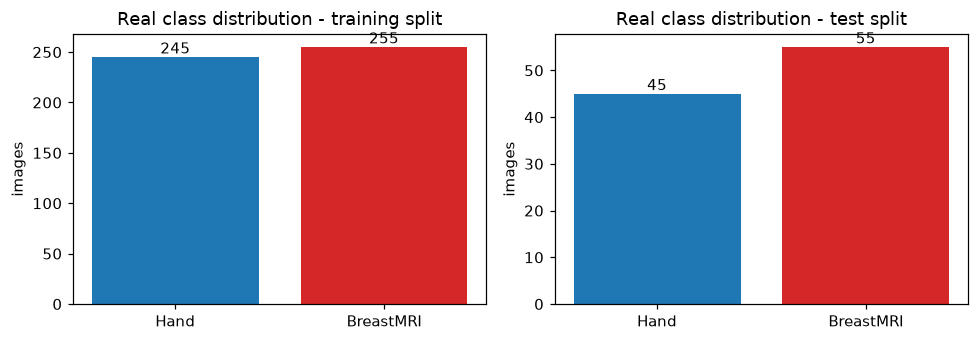

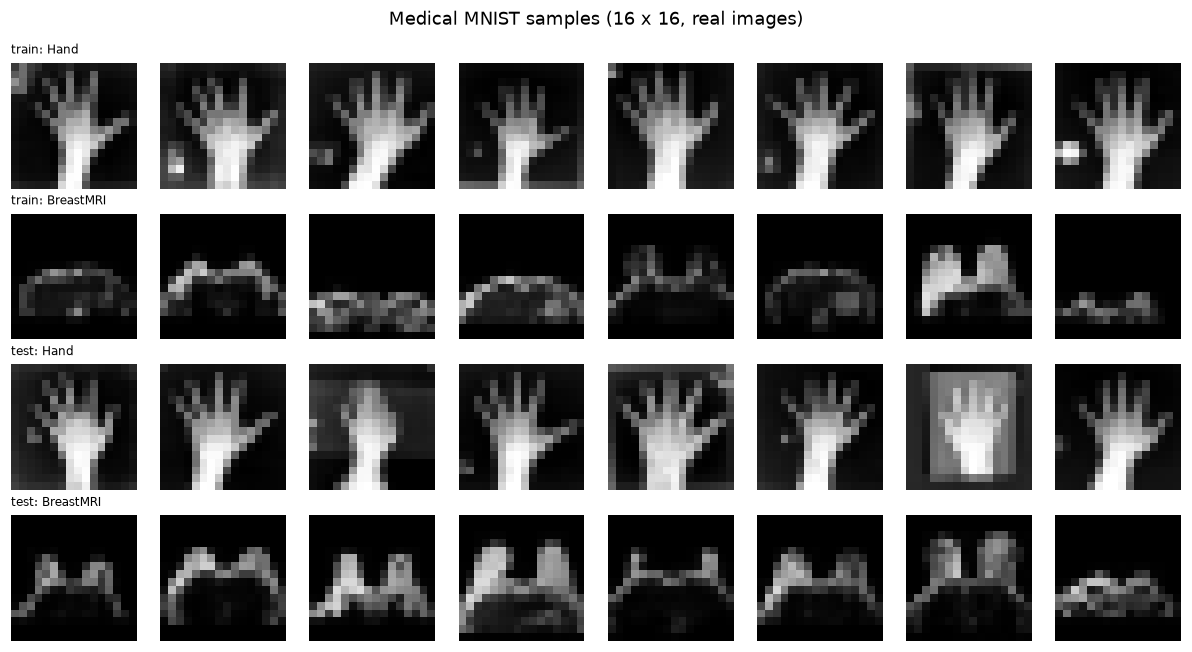

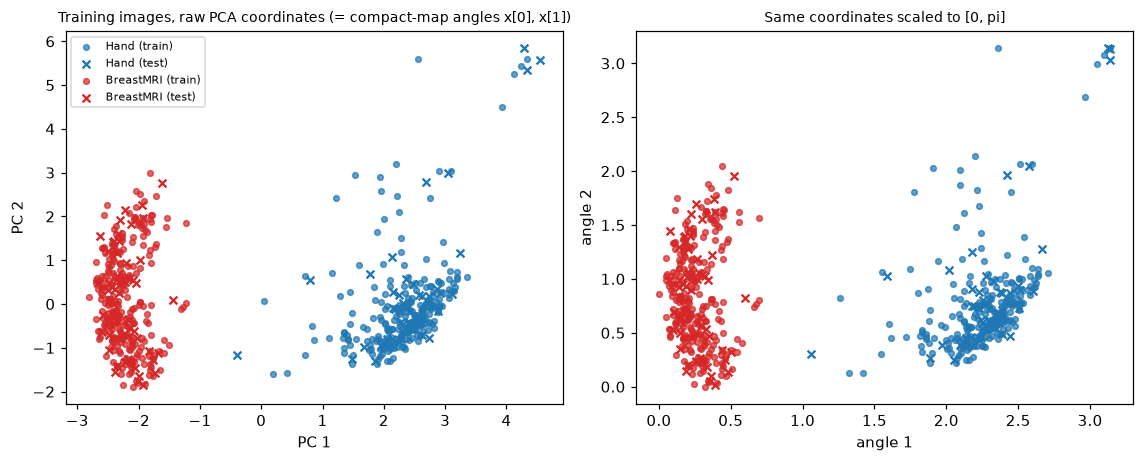

Each point is one real image; colours are the ground-truth labels (two classes only in this task).


In [6]:
# ---- shapes, feature names, labels
print("full sample: ", X_all.shape, "(rows = images, columns = pixels of the 16x16 image)")
feature_names = [f"pixel_{r}_{c}" for r in range(IMG) for c in range(IMG)]
print("feature names:", feature_names[:4], "...", feature_names[-2:], f"({len(feature_names)} in total)")
print("original class labels : Hand ->", -1, "| BreastMRI ->", +1)
print("class counts (all 600): ", dict(zip(*np.unique(y_all, return_counts=True))))
print("class counts (train)  : ", dict(zip(*np.unique(ytr, return_counts=True))))
print("class counts (test)   : ", dict(zip(*np.unique(yte, return_counts=True))))
print("source dataset: Medical MNIST has six classes (AbdomenCT, BreastMRI, CXR, ChestCT, Hand, HeadCT; 58 954 images);")
print("the paper - and this notebook - use only Hand and BreastMRI.")

NAMES = {-1: "Hand", +1: "BreastMRI"}
COL = {-1: "tab:blue", +1: "tab:red"}

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, (title, yy) in zip(ax, [("training split", ytr), ("test split", yte)]):
    cnt = [(yy == -1).sum(), (yy == 1).sum()]
    bars = a.bar(["Hand", "BreastMRI"], cnt, color=[COL[-1], COL[1]])
    a.bar_label(bars); a.set_title(f"Real class distribution - {title}"); a.set_ylabel("images")
plt.tight_layout(); plt.show()

# ---- Fig. 2 of the paper: example images (real samples)
fig, ax = plt.subplots(4, 8, figsize=(11, 6))
for r, (Xs, ys, nm) in enumerate([(Xtr_px, ytr, "train"), (Xte_px, yte, "test")]):
    for k, lab in enumerate([-1, +1]):
        sel = np.where(ys == lab)[0][:8]
        for j, s in enumerate(sel):
            a = ax[2 * r + k, j]; a.imshow(Xs[s].reshape(IMG, IMG), cmap="gray", vmin=0, vmax=1); a.axis("off")
            if j == 0: a.set_title(f"{nm}: {NAMES[lab]}", fontsize=8, loc="left")
plt.suptitle("Medical MNIST samples (16 x 16, real images)"); plt.tight_layout(); plt.show()

# ---- 2-D scatter of the real observations coloured by ground-truth label
# (1) PCA coordinates of the pixels (fitted on the TRAINING split); these are also exactly the first two angles x[0], x[1]
# that the compact feature map encodes, (2) the same coordinates scaled to [0, pi] (the geometry of the input cloud when
# an angle encoding is used).
pca2 = PCA(n_components=2, random_state=SEED).fit(Xtr_px)
P2tr, P2te = pca2.transform(Xtr_px), pca2.transform(Xte_px)
mm2 = MinMaxScaler((0, np.pi)).fit(P2tr)
A2tr, A2te = mm2.transform(P2tr), np.clip(mm2.transform(P2te), 0, np.pi)

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.3))
panels = [("Training images, raw PCA coordinates (= compact-map angles x[0], x[1])", P2tr, P2te, "PC 1", "PC 2"),
          ("Same coordinates scaled to [0, pi]", A2tr, A2te, "angle 1", "angle 2")]
for a, (ttl, tr, te, xl, yl) in zip(ax, panels):
    for lab in (-1, +1):
        a.scatter(tr[ytr == lab, 0], tr[ytr == lab, 1], s=14, c=COL[lab], alpha=.7, label=f"{NAMES[lab]} (train)")
        a.scatter(te[yte == lab, 0], te[yte == lab, 1], s=26, c=COL[lab], marker="x", label=f"{NAMES[lab]} (test)")
    a.set_title(ttl, fontsize=9); a.set_xlabel(xl); a.set_ylabel(yl)
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Each point is one real image; colours are the ground-truth labels (two classes only in this task).")

## 3. Classical baselines (clean data)

Before any attack: RBF-kernel SVM and a random forest on exactly the same inputs as the two quantum models (256 pixels for the large map, 80 PCA angles for the compact map).

In [7]:
def metrics(y_true, y_pred):
    # CHOICE: the paper does not say which F1; we report the support-weighted F1 over the two classes.
    return {"acc": accuracy_score(y_true, y_pred), "f1": f1_score(y_true, y_pred, average="weighted")}

def select_C_rbf(X, y, seed=SEED):
    gs = GridSearchCV(SVC(kernel="rbf", gamma="scale"), {"C": C_GRID},
                      cv=StratifiedKFold(CV_FOLDS, shuffle=True, random_state=seed)).fit(X, y)
    return gs.best_params_["C"]

rows = []
for nm, (A, B) in {"256 pixels": (Xtr_px, Xte_px), "PCA-80 angles": (Ztr, Zte)}.items():
    Cb = select_C_rbf(A, ytr)
    svm = SVC(kernel="rbf", gamma="scale", C=Cb).fit(A, ytr)
    rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=2).fit(A, ytr)
    for model, name in [(svm, f"SVC(rbf, C={Cb})"), (rf, "RandomForest(300)")]:
        rows.append({"input": nm, "model": name, **{f"train_{k}": v for k, v in metrics(ytr, model.predict(A)).items()},
                     **{f"test_{k}": v for k, v in metrics(yte, model.predict(B)).items()}})
baseline_df = pd.DataFrame(rows).round(3)
display(baseline_df)
print("The task is almost trivially separable (hand X-ray vs breast MRI): classical models are also ~100 %.")

,input,model,train_acc,train_f1,test_acc,test_f1
0,256 pixels,"SVC(rbf, C=0.1)",1.0,1.0,1.0,1.0
1,256 pixels,RandomForest(300),1.0,1.0,1.0,1.0
2,PCA-80 angles,"SVC(rbf, C=0.1)",1.0,1.0,1.0,1.0
3,PCA-80 angles,RandomForest(300),1.0,1.0,1.0,1.0


The task is almost trivially separable (hand X-ray vs breast MRI): classical models are also ~100 %.


## 4. The two quantum feature maps and their simulation

Each map is one list of gates: layers of single-qubit rotations (`Rx`, `Rz`, alternating) where gate `g` carries the input `x[g]` (plus the trainable angle `theta[g]` for the first 30 or 20 gates), separated by two layers of CNOT gates. That one list is used twice: to build the Qiskit `QuantumCircuit` that is drawn below, and to drive a fast exact state-vector simulator (an `Rz` layer is a diagonal phase, an `Rx` layer is a Hadamard transform around that phase, a CNOT layer is a permutation of amplitudes). The fast simulator makes 500 x 500 kernel matrices and thousands of attack gradient steps affordable on a CPU. The next cell proves that it computes the same numbers as Qiskit.

In [8]:
# ====== Gate list of the two feature maps ======================================================
N_QUBITS = 10
DIM = 2 ** N_QUBITS

def brick(n, parity):
    return [("cx", q, q + 1) for q in range(parity, n - 1, 2)]

def make_gate_list(blocks, n_train, n=N_QUBITS):
    """blocks = number of rotation layers per block. Layer k is Rx for even k and Rz for odd k (alternating),
    one rotation per qubit; the gate g encodes input component x[g], and for g < n_train also the trainable theta[g].
    After each block two CNOT layers between nearest neighbours (even pairs, then odd pairs) follow."""
    gates, g, layer = [], 0, 0
    for blk in blocks:
        for _ in range(blk):
            for q in range(n):
                kind = "rx" if layer % 2 == 0 else "rz"                       # CHOICE: Rx first, then Rz, alternating
                gates.append(("rot", kind, q, g, g if g < n_train else -1))
                g += 1
            layer += 1
        gates += brick(n, 0) + brick(n, 1)                                    # CHOICE: two CNOT layers = brick-wall pairs
    return gates

# ====== Fast exact state-vector simulator working on exactly this gate list =====================
# Rz layers are diagonal; an Rx layer is H^{(x)n} Rz H^{(x)n}; CNOT layers are index permutations.
_BITS = (np.arange(DIM)[None, :] >> np.arange(N_QUBITS)[:, None]) & 1
SIGN = (1 - 2 * _BITS).astype(float)                 # (10, 1024): +1 where the qubit is |0>, -1 where |1>
_H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
H5 = _H1
for _ in range(4):
    H5 = np.kron(H5, _H1)
H5 = H5.astype(complex)

def wht(psi):
    """Walsh-Hadamard transform H^{(x)10} of every row (two 32x32 matrix products)."""
    v = np.matmul(H5, psi.reshape(psi.shape[0], 32, 32))
    return np.matmul(v, H5).reshape(psi.shape[0], DIM)

def compile_layers(gates):
    ops, i, k = [], 0, 0
    while i < len(gates):
        if gates[i][0] == "rot":
            kind = gates[i][1]
            assert all(gates[i + j][0] == "rot" and gates[i + j][1] == kind and gates[i + j][2] == j for j in range(N_QUBITS))
            ops.append(("layer", kind, k)); k += N_QUBITS; i += N_QUBITS
        else:
            perm = np.arange(DIM)
            while i < len(gates) and gates[i][0] == "cx":
                _, c, t = gates[i]
                m = np.arange(DIM); m = np.where((m >> c) & 1, m ^ (1 << t), m)
                perm = perm[m]; i += 1
            ops.append(("perm", perm, np.argsort(perm)))
    return ops

def _phase(A, k, sign=1):
    return np.exp(-0.5j * sign * (A[:, k:k + N_QUBITS] @ SIGN))

def run_states(ops, A):
    """|phi(x)> for every row of the angle matrix A (batch, n_rot)."""
    psi = np.zeros((A.shape[0], DIM), dtype=complex); psi[:, 0] = 1.0
    for op in ops:
        if op[0] == "layer":
            ph = _phase(A, op[2])
            psi = psi * ph if op[1] == "rz" else wht(wht(psi) * ph)
        else:
            psi = psi[:, op[1]]
    return psi

def grad_angles(ops, A, M):
    """Value and exact gradient (adjoint differentiation) of f = <psi(A)| M |psi(A)> w.r.t. every rotation angle."""
    psi = run_states(ops, A)
    lam = psi @ M.T
    f = np.real(np.einsum("bi,bi->b", psi.conj(), lam))
    grads = np.zeros_like(A)
    for op in reversed(ops):
        if op[0] == "layer":
            k = op[2]
            if op[1] == "rz":
                grads[:, k:k + N_QUBITS] = np.imag((lam.conj() * psi) @ SIGN.T)
                ph = _phase(A, k, -1); psi, lam = psi * ph, lam * ph
            else:
                up, ul = wht(psi), wht(lam)
                grads[:, k:k + N_QUBITS] = np.imag((ul.conj() * up) @ SIGN.T)
                ph = _phase(A, k, -1); psi, lam = wht(up * ph), wht(ul * ph)
        else:
            psi, lam = psi[:, op[2]], lam[:, op[2]]
    return f, grads

class FeatureMap:
    """Parameterised embedding |phi(x; theta)> = U(x, theta)|0^10>; kernel k(a, b) = |<phi(a)|phi(b)>|^2."""
    def __init__(self, name, blocks, n_train, d_in):
        self.name, self.blocks, self.n_train, self.d_in = name, blocks, n_train, d_in
        self.gates = make_gate_list(blocks, n_train)
        self.ops = compile_layers(self.gates)
        self.n_rot = N_QUBITS * sum(blocks)                   # number of angle-encoding gates
    def angles(self, X, theta):
        Xp = np.zeros((X.shape[0], self.n_rot)); Xp[:, :self.d_in] = X        # zero padding (256 -> 260 for the large map)
        Xp[:, :self.n_train] += theta                                          # theta is added to the first components
        return Xp
    def states(self, X, theta, jitter=0.0, rng=None):
        A = self.angles(X, theta)
        if jitter > 0: A = A + rng.normal(0, jitter, A.shape)
        return run_states(self.ops, A)
    def gram(self, XA, theta, XB=None):
        PA = self.states(XA, theta); PB = PA if XB is None else self.states(XB, theta)
        return np.abs(PA.conj() @ PB.T) ** 2
    def qiskit_circuit(self):
        """The executed circuit as a Qiskit QuantumCircuit with symbolic inputs x[.] and trainable t[.]."""
        x = ParameterVector("x", self.n_rot); t = ParameterVector("t", self.n_train)
        qc = QuantumCircuit(N_QUBITS, name=self.name)
        for g in self.gates:
            if g[0] == "rot":
                ang = x[g[3]] + (t[g[4]] if g[4] >= 0 else 0)
                (qc.rx if g[1] == "rx" else qc.rz)(ang, g[2])
            else:
                qc.cx(g[1], g[2])
        return qc, x, t

FMAPS = {"large": FeatureMap("large feature map", [8, 12, 6], 30, 256),     # 26 layers x 10 = 260 gates, 30 trainable
         "compact": FeatureMap("compact feature map", [2, 2, 2, 2], 20, N_PCA)}   # CHOICE: 8 layers x 10 = 80 gates, 20 trainable
for k, fm in FMAPS.items():
    print(f"{fm.name:20s}: {fm.n_rot} encoding gates, {fm.n_train} trainable angles, "
          f"{sum(g[0]=='cx' for g in fm.gates)} CNOTs, {len(fm.ops)} simulator layers")

large feature map   : 260 encoding gates, 30 trainable angles, 27 CNOTs, 29 simulator layers
compact feature map : 80 encoding gates, 20 trainable angles, 36 CNOTs, 12 simulator layers


### Equivalence checks

* the simulated state vectors equal Qiskit's `Statevector` of the drawn circuit (tolerance 1e-10);
* the simulated Gram matrix equals Qiskit's `FidelityStatevectorKernel` (tolerance 1e-9);
* the analytic gradient used by the attack equals central finite differences.

For the gradient: with `M = sum_i alpha_i y_i |phi(x_i)><phi(x_i)|` the decision function is `f(x) = <phi(x)|M|phi(x)> + b`, so `grad f` follows from one forward and one backward sweep through the circuit (adjoint differentiation). The paper obtains the same quantity with the parameter-shift rule (Eq. 14), which needs two kernel evaluations per support vector and input component.

In [9]:
# ---- the fast simulator must reproduce Qiskit exactly (state vectors, kernel entries, gradients)
rng_chk = np.random.default_rng(SEED)
for key, fm in FMAPS.items():
    qc, xv, tv = fm.qiskit_circuit()
    th = rng_chk.uniform(0, 2 * np.pi, fm.n_train)
    Xs = rng_chk.uniform(0, 1, (4, fm.d_in))
    mine = fm.states(Xs, th)
    for b in range(len(Xs)):
        xin = np.zeros(fm.n_rot); xin[:fm.d_in] = Xs[b]
        bound = qc.assign_parameters(dict(zip(list(xv) + list(tv), list(xin) + list(th))))
        assert np.allclose(Statevector(bound).data, mine[b], atol=1e-10), "state-vector mismatch"
    # kernel: Qiskit FidelityStatevectorKernel on the circuit with theta bound == our Gram matrix
    fmap_qiskit = qc.assign_parameters(dict(zip(list(tv), list(th))))
    # the circuit has n_rot data parameters; pad inputs with zeros exactly like FeatureMap.angles does
    pad = lambda Z: np.hstack([Z, np.zeros((len(Z), fm.n_rot - fm.d_in))])
    Kq = FidelityStatevectorKernel(feature_map=fmap_qiskit).evaluate(pad(Xs), pad(Xs[:3]))
    assert np.allclose(Kq, fm.gram(Xs, th, Xs[:3]), atol=1e-9), "kernel mismatch"
    # gradient of f = sum_i c_i k(x_i, x) against central finite differences
    c = rng_chk.normal(size=4)
    Phi = fm.states(Xs, th); M = (Phi.T * c) @ Phi.conj()
    x0 = rng_chk.uniform(0, 1, (1, fm.d_in))
    f0, g = grad_angles(fm.ops, fm.angles(x0, th), M)
    fd = np.zeros(fm.d_in)
    for j in rng_chk.choice(fm.d_in, 6, replace=False):
        e = np.zeros_like(x0); e[0, j] = 1e-6
        fp = grad_angles(fm.ops, fm.angles(x0 + e, th), M)[0]; fmn = grad_angles(fm.ops, fm.angles(x0 - e, th), M)[0]
        assert abs((fp - fmn)[0] / 2e-6 - g[0, j]) < 1e-6, "gradient mismatch"
    print(f"{key:8s}: simulator == Qiskit Statevector (1e-10), == FidelityStatevectorKernel (1e-9), analytic gradient == finite differences")

large   : simulator == Qiskit Statevector (1e-10), == FidelityStatevectorKernel (1e-9), analytic gradient == finite differences


compact : simulator == Qiskit Statevector (1e-10), == FidelityStatevectorKernel (1e-9), analytic gradient == finite differences


## Quantum Circuit Architecture

The circuits below are generated from the gate lists that the simulator runs (`FeatureMap.qiskit_circuit()`), and the cell above asserted that they produce identical state vectors. Reading the drawing from left to right: ten qubits start in |0>; each rotation gate `Rx` or `Rz` encodes one input component (`x[g]`), and in the first gates also a trainable angle (`x[g] + t[g]`); after each block two CNOT layers (a brick-wall of nearest-neighbour pairs) entangle the qubits; the final state `|phi(x)>` is not measured directly. The kernel entry `k(a, b)` is the squared overlap `|<phi(a)|phi(b)>|^2`, which on hardware is estimated by running `U(a)` followed by `U(b)^dagger` and counting how often all qubits are measured as 0 (the paper's QKE, 1024 shots). The large map's four extra inputs `x[256..259]` are zero padding, as in the paper. Where the paper omits details (gate order inside layers, which CNOT pairs, the compact map layout) the choices are listed in the table at the top.

=== large feature map (executed circuit) ===
qubits: 10 | depth: 32 | trainable parameters: 30 | data-encoding parameters: 260 (256 real inputs + 4 zero padding) | gate counts: {'rx': 130, 'rz': 130, 'cx': 27}


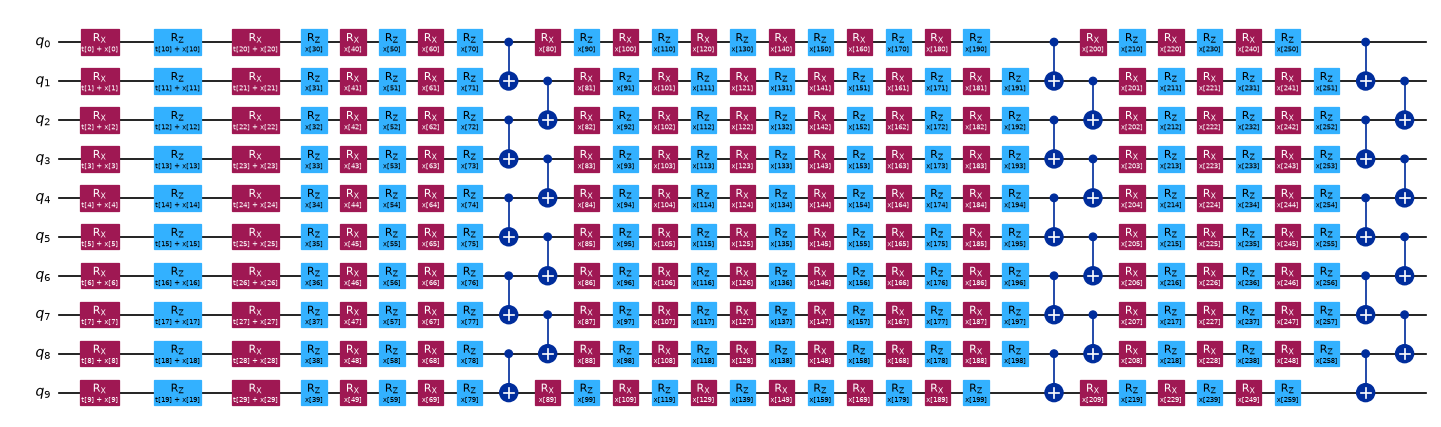

=== compact feature map (executed circuit) ===
qubits: 10 | depth: 16 | trainable parameters: 20 | data-encoding parameters: 80 (80 real inputs + 0 zero padding) | gate counts: {'rx': 40, 'rz': 40, 'cx': 36}


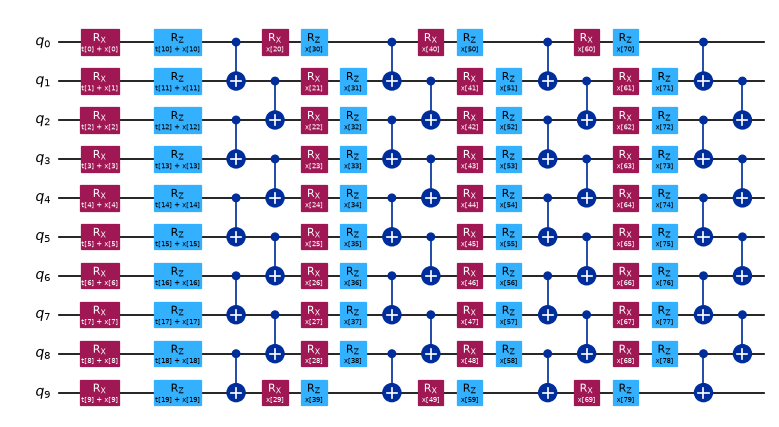

In [10]:
for key, fm in FMAPS.items():
    qc, xv, tv = fm.qiskit_circuit()
    print(f"=== {fm.name} (executed circuit) ===")
    print("qubits:", qc.num_qubits, "| depth:", qc.depth(), "| trainable parameters:", len(tv),
          "| data-encoding parameters:", len(xv), f"({fm.d_in} real inputs + {fm.n_rot - fm.d_in} zero padding)",
          "| gate counts:", dict(qc.count_ops()))
    fig = qc.draw("mpl", fold=-1, scale=0.55, plot_barriers=False)
    display(fig); plt.close(fig)

## 5. Kernel alignment: training the embedding angles

The embedding has trainable angles `theta` (30 for the large map, 20 for the compact one). As in the paper (appendix A) they are chosen by solving a min-max problem: for fixed `theta` the SVM maximises its dual objective, then `theta` is moved to *minimise* that objective, which tightens a bound on the generalisation error. SPSA (learning rate 0.05, perturbation 0.05) does the minimisation. In `FAST_MODE` only a handful of iterations are run, so the kernel is hardly trained; the full mode uses the paper's 80.

In [11]:
# ---- kernel-target alignment as in the paper (appendix A): minimise the SVM dual objective over the embedding angles
def dual_objective(K, y, C=1.0):
    """F = sum_i alpha_i - 1/2 sum_ij alpha_i alpha_j y_i y_j K_ij for the SVM fitted on K (Qiskit's SVCLoss)."""
    svc = SVC(kernel="precomputed", C=C).fit(K, y)
    c = svc.dual_coef_[0]                                    # = alpha_i * y_i on the support vectors
    sv = svc.support_
    return float(np.abs(c).sum() - 0.5 * c @ K[np.ix_(sv, sv)] @ c)

def train_kernel(fm, X, y, iters, seed):
    rng = np.random.default_rng(seed)
    theta0 = rng.uniform(0, 2 * np.pi, fm.n_train)           # CHOICE: random initial angles in [0, 2 pi) ("random parameters")
    hist = []
    loss = lambda th: dual_objective(fm.gram(X, th), y)
    opt = SPSA(maxiter=iters, learning_rate=SPSA_LR, perturbation=SPSA_PERT,
               callback=lambda nfev, params, fx, step, acc: hist.append(fx))
    res = opt.minimize(loss, theta0)
    return theta0, np.asarray(res.x), np.array(hist), loss(theta0), loss(np.asarray(res.x))

large   : SPSA 2 iterations in 101s | SVM dual objective 23.3 -> 20.7 (paper: ~8 large / ~11 compact after 80 iterations)


compact : SPSA 4 iterations in 62s | SVM dual objective 25.6 -> 24.6 (paper: ~8 large / ~11 compact after 80 iterations)


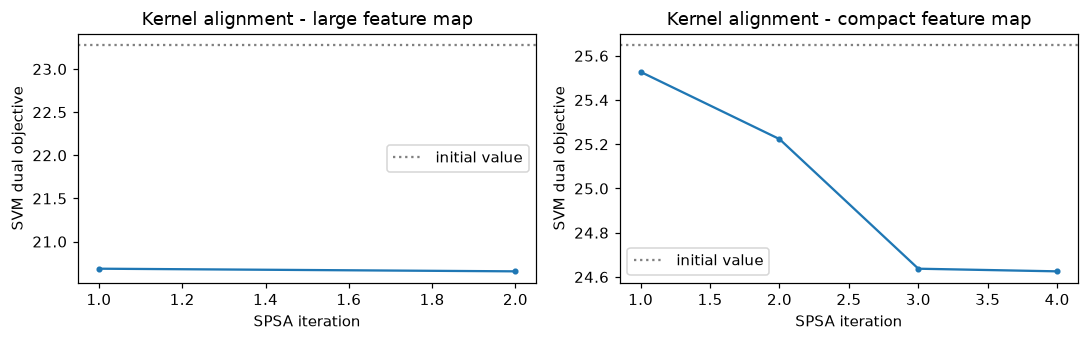

trained kernels == Qiskit FidelityStatevectorKernel


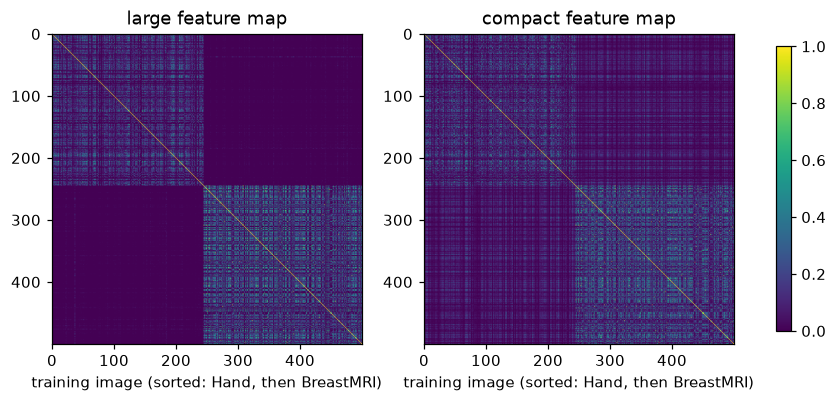

large   : off-diagonal kernel entries mean 0.071, std 0.131, 5-95 % range [0.000, 0.377], share of entries > 0.1: 0.22
compact : off-diagonal kernel entries mean 0.098, std 0.121, 5-95 % range [0.001, 0.360], share of entries > 0.1: 0.33


In [12]:
trained = {}
IN_ = {"large": (Xtr_px, Xte_px), "compact": (Ztr, Zte)}      # model inputs per feature map
t0 = time.time()
for key, fm in FMAPS.items():
    tt = time.time()
    th0, th, hist, L0, L1 = train_kernel(fm, IN_[key][0], ytr, SPSA_ITERS[key], SEED)
    trained[key] = dict(theta0=th0, theta=th, hist=hist, loss0=L0, loss1=L1)
    print(f"{key:8s}: SPSA {SPSA_ITERS[key]} iterations in {time.time()-tt:.0f}s | SVM dual objective {L0:.1f} -> {L1:.1f}"
          f" (paper: ~8 large / ~11 compact after 80 iterations)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, key in zip(ax, FMAPS):
    h = trained[key]["hist"]
    a.plot(np.arange(1, len(h) + 1), h, "o-", ms=3); a.axhline(trained[key]["loss0"], ls=":", c="gray", label="initial value")
    a.set_title(f"Kernel alignment - {key} feature map"); a.set_xlabel("SPSA iteration"); a.set_ylabel("SVM dual objective"); a.legend()
plt.tight_layout(); plt.show()

# the trained kernel, again checked against Qiskit
for key, fm in FMAPS.items():
    qc, xv, tv = fm.qiskit_circuit()
    fq = qc.assign_parameters(dict(zip(list(tv), list(trained[key]["theta"]))))
    A = IN_[key][0][:4]; pad = lambda Z: np.hstack([Z, np.zeros((len(Z), fm.n_rot - fm.d_in))])
    assert np.allclose(FidelityStatevectorKernel(feature_map=fq).evaluate(pad(A)), fm.gram(A, trained[key]["theta"]), atol=1e-9)
print("trained kernels == Qiskit FidelityStatevectorKernel")

# Fig. 5 analogue: training kernel matrices (rows/columns sorted by class so that the block structure is visible)
order = np.argsort(ytr, kind="stable")
Ktr_all = {key: FMAPS[key].gram(IN_[key][0], trained[key]["theta"]) for key in FMAPS}
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, key in zip(ax, FMAPS):
    im = a.imshow(Ktr_all[key][np.ix_(order, order)], vmin=0, vmax=1, cmap="viridis"); a.set_title(f"{key} feature map")
    a.set_xlabel("training image (sorted: Hand, then BreastMRI)")
fig.colorbar(im, ax=ax.tolist(), shrink=0.8); plt.show()
for key in FMAPS:
    K = Ktr_all[key]; off = K[~np.eye(len(K), dtype=bool)]
    print(f"{key:8s}: off-diagonal kernel entries mean {off.mean():.3f}, std {off.std():.3f}, 5-95 % range "
          f"[{np.percentile(off,5):.3f}, {np.percentile(off,95):.3f}], share of entries > 0.1: {(off>0.1).mean():.2f}")

## 6. Two SVM classes with exact gradients

`QSVM` fits `sklearn.svm.SVC(kernel="precomputed")` on the quantum Gram matrix (embedding angles fixed) and exposes the decision function and its gradient with respect to the input. `RBFSVM` is the classical counterpart with the analytic gradient of an RBF kernel.

In [13]:
def pad_to(fm, Z):
    return Z   # (padding to the circuit width is done inside FeatureMap.angles)

class QSVM:
    """Quantum-kernel SVM with a fixed embedding. f(x) = sum_i alpha_i y_i k(x_i, x) + b = <phi(x)|M|phi(x)> + b,
    where M = sum_i alpha_i y_i |phi(x_i)><phi(x_i)|, which gives the exact gradient of f by adjoint differentiation."""
    def __init__(self, fm, theta, X, y, C=None, seed=SEED):
        self.fm, self.theta, self.X, self.y = fm, theta, X, y
        self.Phi = fm.states(X, theta)
        self.K = np.abs(self.Phi.conj() @ self.Phi.T) ** 2
        if C is None:
            gs = GridSearchCV(SVC(kernel="precomputed"), {"C": C_GRID},
                              cv=StratifiedKFold(CV_FOLDS, shuffle=True, random_state=seed)).fit(self.K, y)
            C = gs.best_params_["C"]
        self.C = C
        self.svc = SVC(kernel="precomputed", C=C).fit(self.K, y)
        sv, c = self.svc.support_, self.svc.dual_coef_[0]
        self.b = float(self.svc.intercept_[0])
        self.M = (self.Phi[sv].T * c) @ self.Phi[sv].conj()
    def decision(self, X, jitter=0.0, rng=None):
        P = self.fm.states(X, self.theta, jitter, rng)
        return np.real(np.einsum("bi,ij,bj->b", P.conj(), self.M, P)) + self.b
    def predict(self, X, **kw):
        return np.where(self.decision(X, **kw) >= 0, 1, -1)
    def fg(self, X):
        f, g = grad_angles(self.fm.ops, self.fm.angles(X, self.theta), self.M)
        return f + self.b, g[:, :self.fm.d_in]

class RBFSVM:
    """Classical RBF-kernel SVM with the analytic gradient of its decision function (for the same attack)."""
    def __init__(self, X, y, C=None, seed=SEED):
        self.X, self.y = X, y
        self.C = C if C is not None else select_C_rbf(X, y, seed)
        self.svc = SVC(kernel="rbf", gamma="scale", C=self.C).fit(X, y)
        self.gamma = self.svc._gamma
    def decision(self, X, **kw):
        return self.svc.decision_function(X)
    def predict(self, X, **kw):
        return np.where(self.decision(X) >= 0, 1, -1)
    def fg(self, X):
        sv, c = self.svc.support_vectors_, self.svc.dual_coef_[0]
        d2 = ((X[:, None, :] - sv[None, :, :]) ** 2).sum(-1)
        k = np.exp(-self.gamma * d2)
        f = k @ c + self.svc.intercept_[0]
        g = np.einsum("bs,sd,s->bd", k, sv, c) * 2 * self.gamma - (k * c).sum(1)[:, None] * 2 * self.gamma * X
        return f, g

# gradient check of the classical model (finite differences)
_rb = RBFSVM(Xtr_px, ytr, C=1.0); _x = Xte_px[:1].copy(); _g = _rb.fg(_x)[1][0]
for j in (3, 100, 200):
    e = np.zeros_like(_x); e[0, j] = 1e-6
    assert abs((_rb.fg(_x + e)[0] - _rb.fg(_x - e)[0])[0] / 2e-6 - _g[j]) < 1e-6
print("RBF-SVM analytic gradient == finite differences")

RBF-SVM analytic gradient == finite differences


## 7. Evasion attack and adversarial training (paper section 4.2)

`attack` is Eq. (11). `protocol` runs the whole story for one model family:

1. fit the standard model (5-fold CV for `C`) and record Tables II/III;
2. attack `N_ADV` correctly classified training images, keep the successful ones;
3. split them 41 : 9 (stratified), append the 9 to the test set (extended test set) and report Table IV;
4. adversarial training: append the 41 to the training set, re-select `C`, refit with the embedding fixed, report Table V;
5. **extra (not in the paper):** attack fresh test images (a) against the standard model and feed the results to the defended model ("new attacks"), and (b) directly against the defended model, to see whether its perturbations must be larger (these extra attacks use the cheaper adaptive step described in section 8).

The step rule of `attack` is the paper's constant `eta = 0.01` in this section. Attacked images that have not flipped after `ATTACK_MAX_ITERS` steps are dropped (their number is printed): in `FAST_MODE` the cap is low, so the success rate is below the paper's 100 %.

In [14]:
def attack(fg, X0, y, eta, max_iters, mode="constant"):
    """Paper Eq. (11): x_{t+1} = x_t - eta_t * y * grad f(x_t) (white-box evasion attack, hinge loss).
    mode="constant": eta_t = eta = 0.01 (the paper's appendix B setting).
    mode="adaptive": eta_t = max(eta, |f(x_t)| / ||grad f(x_t)||^2), the paper's Eq. (13) with the constant eta as floor
    (the paper suggests this replacement when Eq. (13) gets very small). It reaches the decision surface in far fewer steps
    and is used where a constant eta is too slow (classical RBF models, like-for-like comparison, repeated draws).
    The iteration of a sample stops as soon as y * f(x) < 0 (the sample is on the other side of the decision surface).
    Returns adversarial inputs, success flags and the number of gradient steps per sample."""
    X = X0.copy(); n = len(X); iters = np.full(n, -1); done = np.zeros(n, bool)
    f0 = fg(X)[0]
    active = (y * f0) > 0                                # only correctly classified samples are attacked
    start_ok = active.copy()
    for it in range(max_iters + 1):
        idx = np.where(active)[0]
        if len(idx) == 0: break
        f, g = fg(X[idx])
        flipped = (y[idx] * f) < 0
        iters[idx[flipped]] = it; done[idx[flipped]] = True; active[idx[flipped]] = False
        if it == max_iters: break
        keep = ~flipped
        step = eta
        if mode == "adaptive":
            step = np.maximum(eta, np.abs(f[keep]) / np.maximum((g[keep] ** 2).sum(1), 1e-12))[:, None]
        X[idx[keep]] -= step * y[idx[keep], None] * g[keep]
    return X, done, iters, start_ok

def confusion(y_true, y_pred):
    # rows: predicted (Hand, Breast); columns: true (Hand, Breast) -- same layout as the paper's tables
    return confusion_matrix(y_true, y_pred, labels=[-1, 1]).T

def protocol(build, Xtr, ytr, Xte, yte, seed, label="", verbose=True, mode="constant", std=None):
    """Paper section 4.2 for one model family. `build(X, y)` returns a fitted model with predict/decision/fg.
    `std` may pass an already fitted standard model; `mode` selects the attack step rule (see `attack`)."""
    rng = np.random.default_rng(seed)
    std = std if std is not None else build(Xtr, ytr)
    res = {"label": label, "C_std": std.C, "std_model": std}
    res["std_train"] = metrics(ytr, std.predict(Xtr)); res["std_test"] = metrics(yte, std.predict(Xte))
    res["std_cm"] = confusion(yte, std.predict(Xte))
    # --- 1. choose N_ADV correctly classified TRAINING images, balanced over the two classes (CHOICE: source = training set)
    ok = np.where(std.predict(Xtr) == ytr)[0]
    per = N_ADV // 2
    order = rng.permutation(len(Xtr))                    # model-independent given the seed, so models share most attacked images
    is_ok = np.zeros(len(Xtr), bool); is_ok[ok] = True
    pick = lambda lab, n: [i for i in order if ytr[i] == lab and is_ok[i]][:n]
    src = np.array(pick(-1, per) + pick(1, N_ADV - per))
    t0 = time.time()
    Xadv, done, iters, _ = attack(std.fg, Xtr[src], ytr[src], ETA, ATTACK_MAX_ITERS, mode)
    res["attack_time"] = time.time() - t0
    res["attack_success"] = done.mean(); res["attack_iters"] = iters[done]
    res["l2"] = np.linalg.norm(Xadv[done] - Xtr[src][done], axis=1)
    s = np.where(done)[0]
    if len(s) < 4:
        raise RuntimeError(f"{label}: only {len(s)} successful attacks within {ATTACK_MAX_ITERS} steps - raise ATTACK_MAX_ITERS or use mode='adaptive'")
    res.update(src=src[s], Xadv=Xadv[s], yadv=ytr[src][s], Xorig=Xtr[src][s])
    # --- 2. stratified split into adversarial-train / adversarial-test (paper: 41 / 9 of 50)
    n_tr = int(np.clip(round(len(s) * 41 / 50), 2, len(s) - 2))   # same 41 : 9 proportion as the paper
    a_tr, a_te = train_test_split(np.arange(len(s)), train_size=n_tr, stratify=res["yadv"], random_state=seed)
    res.update(a_tr=a_tr, a_te=a_te)
    Xext, yext = np.vstack([Xte, Xadv[s][a_te]]), np.r_[yte, res["yadv"][a_te]]
    res["ext_n"] = len(yext); res["n_adv_train"] = len(a_tr); res["n_adv_test"] = len(a_te)
    res["std_ext"] = metrics(yext, std.predict(Xext)); res["std_ext_cm"] = confusion(yext, std.predict(Xext))
    # --- 3. adversarial training: extend the training set, keep the embedding fixed, re-select C by CV
    Xaug, yaug = np.vstack([Xtr, Xadv[s][a_tr]]), np.r_[ytr, res["yadv"][a_tr]]
    at = build(Xaug, yaug)
    res["at_model"] = at; res["C_at"] = at.C
    res["at_train"] = metrics(yaug, at.predict(Xaug)); res["at_test_clean"] = metrics(yte, at.predict(Xte))
    res["at_ext"] = metrics(yext, at.predict(Xext)); res["at_ext_cm"] = confusion(yext, at.predict(Xext))
    # accuracy on the held-out adversarial images alone (the paper's Table IV: 0 of 9; Table V: 9 of 9)
    res["std_adv_acc"] = float((std.predict(Xadv[s][a_te]) == res["yadv"][a_te]).mean())
    res["at_adv_acc"] = float((at.predict(Xadv[s][a_te]) == res["yadv"][a_te]).mean())
    # --- 4. NEW attacks (extra experiment): fresh test images, crafted against the standard model and against the AT model
    cand = np.where((std.predict(Xte) == yte) & (at.predict(Xte) == yte))[0]
    k = min(N_NEW_ATTACK, len(cand)); sel = rng.choice(cand, k, replace=False)
    # (the fresh attacks always use the cheap adaptive step; they are an extra experiment, not a paper table)
    Xs_adv, d_s, it_s, _ = attack(std.fg, Xte[sel], yte[sel], ETA, NEW_ATTACK_MAX_ITERS, "adaptive")
    Xa_adv, d_a, it_a, _ = attack(at.fg, Xte[sel], yte[sel], ETA, NEW_ATTACK_MAX_ITERS, "adaptive")
    res["new_n"] = k; res["mode"] = mode
    res["new_std_success"], res["new_at_success"] = d_s.mean(), d_a.mean()
    res["new_std_iters"], res["new_at_iters"] = it_s[d_s], it_a[d_a]
    res["new_std_l2"] = np.linalg.norm(Xs_adv[d_s] - Xte[sel][d_s], axis=1)
    res["new_at_l2"] = np.linalg.norm(Xa_adv[d_a] - Xte[sel][d_a], axis=1)
    res["transfer_acc_at"] = float((at.predict(Xs_adv[d_s]) == yte[sel][d_s]).mean()) if d_s.any() else np.nan
    res["new_adv_std"] = (Xs_adv, d_s, sel)
    if verbose:
        print(f"[{label}] standard C={std.C}: train acc {res['std_train']['acc']:.3f}, test acc {res['std_test']['acc']:.3f}, "
              f"F1 {res['std_test']['f1']:.3f}")
        print(f"[{label}] attack ({mode}, eta={ETA}): {done.sum()}/{len(done)} successful in {res['attack_time']:.0f}s; gradient steps: "
              f"median {np.median(iters[done]) if done.any() else np.nan:.0f}, max {iters[done].max() if done.any() else np.nan}")
        print(f"[{label}] extended test set ({res['ext_n']} = {len(yte)} clean + {len(a_te)} adversarial): "
              f"standard acc {res['std_ext']['acc']:.3f} F1 {res['std_ext']['f1']:.3f} | after adversarial training "
              f"(C={at.C}) acc {res['at_ext']['acc']:.3f} F1 {res['at_ext']['f1']:.3f}")
    return res

### 7.1 The quantum models

In [15]:
RES = {}
BUILD = {"large": lambda X, y: QSVM(FMAPS["large"], trained["large"]["theta"], X, y),
         "compact": lambda X, y: QSVM(FMAPS["compact"], trained["compact"]["theta"], X, y)}
for key in FMAPS:
    t0 = time.time()
    RES[key] = protocol(BUILD[key], IN_[key][0], ytr, IN_[key][1], yte, SEED, label=f"QSVM {key}")
    print(f"   ({time.time()-t0:.0f}s)\n")

[QSVM large] standard C=0.5: train acc 1.000, test acc 1.000, F1 1.000
[QSVM large] attack (constant, eta=0.01): 35/50 successful in 245s; gradient steps: median 17, max 147
[QSVM large] extended test set (106 = 100 clean + 6 adversarial): standard acc 0.943 F1 0.943 | after adversarial training (C=1.0) acc 1.000 F1 1.000
   (468s)



[QSVM compact] standard C=0.5: train acc 1.000, test acc 1.000, F1 1.000
[QSVM compact] attack (constant, eta=0.01): 37/50 successful in 167s; gradient steps: median 50, max 133
[QSVM compact] extended test set (107 = 100 clean + 7 adversarial): standard acc 0.935 F1 0.935 | after adversarial training (C=1.0) acc 1.000 F1 1.000
   (334s)



### 7.2 Tables III-V of the paper, recomputed

Rows are predicted, columns true labels. The test accuracy of the *standard* model on the extended test set is lower than on the clean test set because the adversarial images are misclassified by construction.

In [16]:
def cm_df(cm): return pd.DataFrame(cm, index=["pred Hand", "pred Breast"], columns=["true Hand", "true Breast"])
for key in FMAPS:
    r = RES[key]
    print(f"================ {key} feature map ================")
    print("Table II  (standard training)   train acc %.2f | test acc %.2f | test F1 %.2f | C = %s" %
          (r["std_train"]["acc"], r["std_test"]["acc"], r["std_test"]["f1"], r["C_std"]))
    print("Table III (confusion matrix, test set)"); display(cm_df(r["std_cm"]))
    print("Table IV  (standard model, test set + %d adversarial)  acc %.2f | F1 %.2f" %
          (r["n_adv_test"], r["std_ext"]["acc"], r["std_ext"]["f1"])); display(cm_df(r["std_ext_cm"]))
    print("Table V   (after adversarial training, same extended test set) train acc %.2f | test acc %.2f | F1 %.2f | C = %s" %
          (r["at_train"]["acc"], r["at_ext"]["acc"], r["at_ext"]["f1"], r["C_at"])); display(cm_df(r["at_ext_cm"]))

================ large feature map ================
Table II  (standard training)   train acc 1.00 | test acc 1.00 | test F1 1.00 | C = 0.5
Table III (confusion matrix, test set)


,true Hand,true Breast
pred Hand,45,0
pred Breast,0,55


Table IV  (standard model, test set + 6 adversarial)  acc 0.94 | F1 0.94


,true Hand,true Breast
pred Hand,45,4
pred Breast,2,55


Table V   (after adversarial training, same extended test set) train acc 1.00 | test acc 1.00 | F1 1.00 | C = 1.0


...

,true Hand,true Breast
pred Hand,45,0
pred Breast,0,55


Table IV  (standard model, test set + 7 adversarial)  acc 0.93 | F1 0.93


,true Hand,true Breast
pred Hand,45,5
pred Breast,2,55


Table V   (after adversarial training, same extended test set) train acc 1.00 | test acc 1.00 | F1 1.00 | C = 1.0


,true Hand,true Breast
pred Hand,47,0
pred Breast,0,60


### 7.3 Adversarial images (paper Fig. 6)

Top row: original training images. Rows 2 and 3: the same images after the attack on the large and the compact model. Rows 4 and 5: the perturbation (adversarial minus original; for the compact map, minus the PCA reconstruction of the original, so only the attack is visible). The bottom histograms show how close the training images are to the decision surface and how many gradient steps the attack needed.

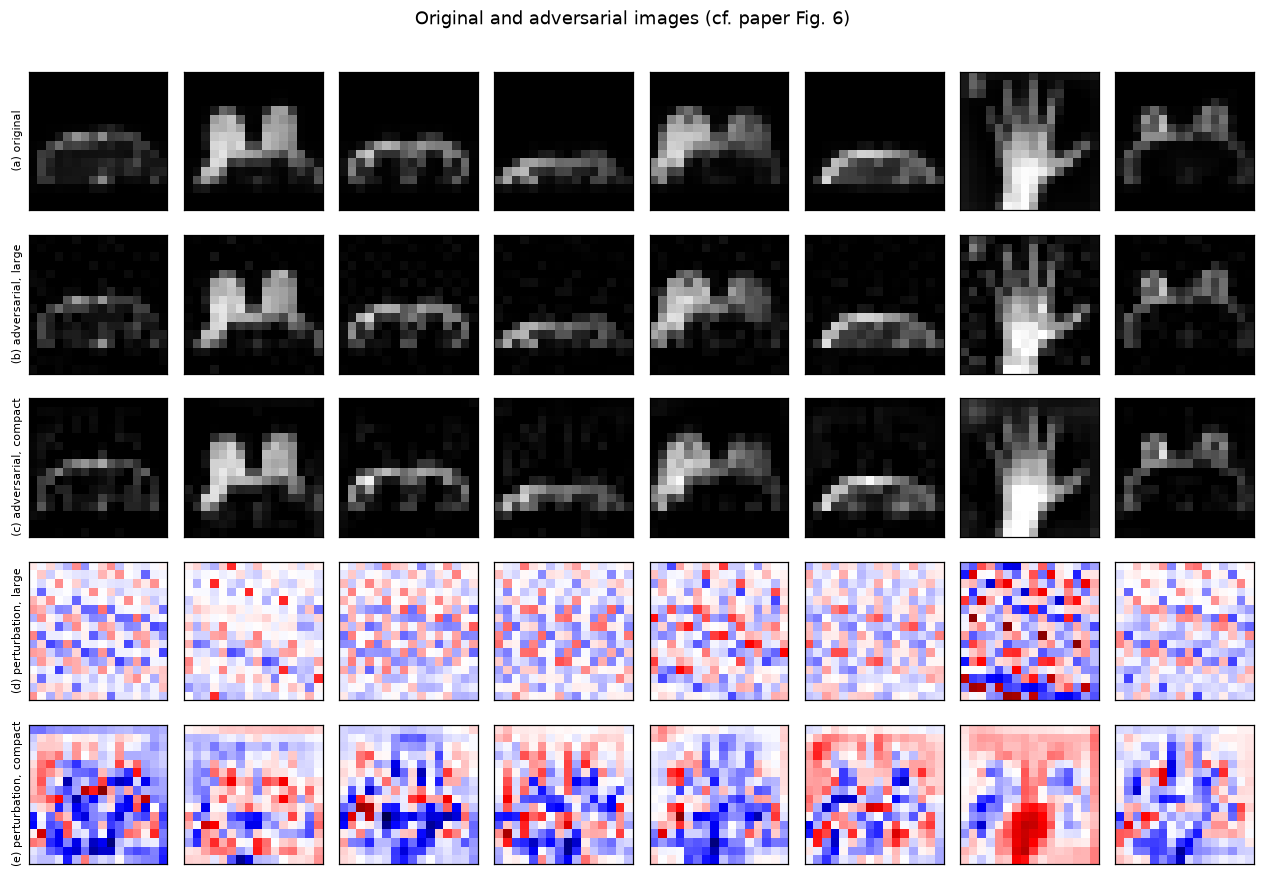

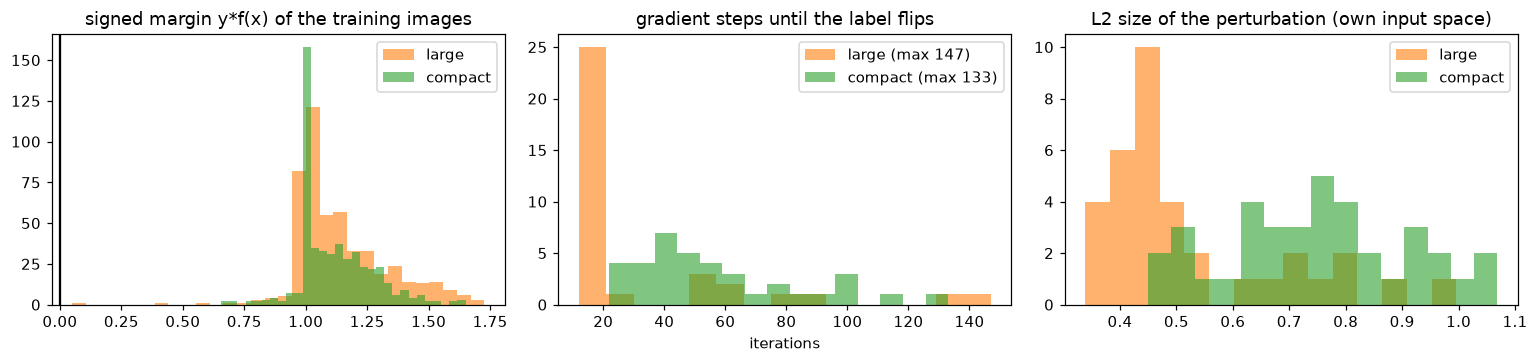

In [17]:
# Fig. 6 analogue: original image, adversarial images for the large and the compact map, and the perturbations.
rl, rc = RES["large"], RES["compact"]
# images attacked in BOTH models (same training image) are shown in the same column when available
common = np.intersect1d(rl["src"], rc["src"])
ncol = 8
if len(common) >= 4:
    cols = common[:ncol]
    gl = {s: j for j, s in enumerate(rl["src"])}; gc = {s: j for j, s in enumerate(rc["src"])}
    orig = Xtr_px[cols]
    adv_l = rl["Xadv"][[gl[s] for s in cols]]
    adv_c = from_compact(rc["Xadv"][[gc[s] for s in cols]])
    orig_c = from_compact(Ztr[cols])               # PCA reconstruction of the original, so that (e) is the attack alone
else:                                              # fall back: show the first images of each model independently
    cols = np.arange(ncol)
    orig = rl["Xorig"][:ncol]; adv_l = rl["Xadv"][:ncol]
    orig_c = from_compact(rc["Xorig"][:ncol]); adv_c = from_compact(rc["Xadv"][:ncol])
n = min(ncol, len(orig), len(adv_l), len(adv_c))
fig, ax = plt.subplots(5, n, figsize=(1.45 * n, 8))
ax = np.atleast_2d(ax).reshape(5, n)
rows = [("(a) original", orig, "gray", (0, 1)), ("(b) adversarial, large", adv_l, "gray", (0, 1)),
        ("(c) adversarial, compact", adv_c, "gray", (0, 1)), ("(d) perturbation, large", adv_l - orig, "seismic", None),
        ("(e) perturbation, compact", adv_c - orig_c, "seismic", None)]
vmax = max(np.abs(adv_l - orig).max(), np.abs(adv_c - orig_c).max())
for r, (ttl, data, cmap, lim) in enumerate(rows):
    for j in range(n):
        a = ax[r, j]
        if lim: a.imshow(data[j].reshape(IMG, IMG), cmap=cmap, vmin=lim[0], vmax=lim[1])
        else:   a.imshow(data[j].reshape(IMG, IMG), cmap=cmap, vmin=-vmax, vmax=vmax)
        a.set_xticks([]); a.set_yticks([])
        if j == 0: a.set_ylabel(ttl, fontsize=7)
plt.suptitle("Original and adversarial images (cf. paper Fig. 6)", y=1.0); plt.tight_layout(); plt.show()

# how far the attacked images are from the decision surface, and how many steps the attack needs
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for key, col in zip(FMAPS, ["tab:orange", "tab:green"]):
    r = RES[key]; std = r["std_model"]
    ax[0].hist(std.decision(IN_[key][0]) * ytr, bins=30, alpha=.6, color=col, label=f"{key}")
    ax[1].hist(r["attack_iters"], bins=15, alpha=.6, color=col, label=f"{key} (max {r['attack_iters'].max() if len(r['attack_iters']) else 0})")
    ax[2].hist(r["l2"], bins=15, alpha=.6, color=col, label=key)
ax[0].axvline(0, c="k"); ax[0].set_title("signed margin y*f(x) of the training images"); ax[0].legend()
ax[1].set_title("gradient steps until the label flips"); ax[1].set_xlabel("iterations"); ax[1].legend()
ax[2].set_title("L2 size of the perturbation (own input space)"); ax[2].legend()
plt.tight_layout(); plt.show()

## 8. The same attack on a classical RBF-SVM

Identical inputs (256 pixels and 80 PCA scores), identical adversarial-training protocol, and one attack for all four models. A constant step `eta = 0.01` (section 7) needs thousands of steps on a classical RBF-SVM, whose gradients are small, so this comparison uses the *adaptive* step of the paper's Eq. (13), `eta_t = max(0.01, |f| / ||grad f||^2)`, which the paper itself suggests (the step that would land exactly on the linearised decision surface, with the constant as a floor). The two quantum models are therefore attacked a second time with this rule. This tests whether the vulnerability is specific to the quantum kernel.

In [18]:
# Like-for-like comparison: the SAME attack for all four models. A constant step eta = 0.01 needs thousands of steps on the
# classical RBF models (small gradients), so the adaptive variant (paper Eq. 13 with eta as floor) is used for everyone.
CRES = {}
CRES["q_large"]   = protocol(BUILD["large"],   Xtr_px, ytr, Xte_px, yte, SEED, label="QSVM large", mode="adaptive", std=RES["large"]["std_model"])
CRES["q_compact"] = protocol(BUILD["compact"], Ztr, ytr, Zte, yte, SEED, label="QSVM compact", mode="adaptive", std=RES["compact"]["std_model"])
CRES["rbf_px"]    = protocol(lambda X, y: RBFSVM(X, y), Xtr_px, ytr, Xte_px, yte, SEED, label="RBF-SVM 256 px", mode="adaptive")
CRES["rbf_pca"]   = protocol(lambda X, y: RBFSVM(X, y), Ztr, ytr, Zte, yte, SEED, label="RBF-SVM PCA-80", mode="adaptive")

[QSVM large] standard C=0.5: train acc 1.000, test acc 1.000, F1 1.000
[QSVM large] attack (adaptive, eta=0.01): 50/50 successful in 137s; gradient steps: median 3, max 125
[QSVM large] extended test set (109 = 100 clean + 9 adversarial): standard acc 0.917 F1 0.917 | after adversarial training (C=2.0) acc 0.972 F1 0.972


[QSVM compact] standard C=0.5: train acc 1.000, test acc 1.000, F1 1.000
[QSVM compact] attack (adaptive, eta=0.01): 50/50 successful in 108s; gradient steps: median 3, max 141
[QSVM compact] extended test set (109 = 100 clean + 9 adversarial): standard acc 0.917 F1 0.917 | after adversarial training (C=1.0) acc 0.982 F1 0.982


[RBF-SVM 256 px] standard C=0.1: train acc 1.000, test acc 1.000, F1 1.000
[RBF-SVM 256 px] attack (adaptive, eta=0.01): 46/50 successful in 2s; gradient steps: median 2, max 4
[RBF-SVM 256 px] extended test set (108 = 100 clean + 8 adversarial): standard acc 0.926 F1 0.926 | after adversarial training (C=0.5) acc 1.000 F1 1.000


[RBF-SVM PCA-80] standard C=0.1: train acc 1.000, test acc 1.000, F1 1.000
[RBF-SVM PCA-80] attack (adaptive, eta=0.01): 40/50 successful in 1s; gradient steps: median 4, max 4
[RBF-SVM PCA-80] extended test set (107 = 100 clean + 7 adversarial): standard acc 0.935 F1 0.935 | after adversarial training (C=1.0) acc 0.981 F1 0.981


In [19]:
def row(name, r):
    return {"model": name, "C std / AT": f"{r['C_std']} / {r['C_at']}",
            "clean test acc": round(r["std_test"]["acc"], 3),
            "attack success": f"{r['attack_success']*100:.0f} %",
            "median steps": float(np.median(r["attack_iters"])) if len(r["attack_iters"]) else np.nan,
            "median L2": round(float(np.median(r["l2"])), 3) if len(r["l2"]) else np.nan,
            "acc ext. test (std)": round(r["std_ext"]["acc"], 3), "acc ext. test (adv. trained)": round(r["at_ext"]["acc"], 3),
            "AT acc on fresh adv. (transfer)": round(r["transfer_acc_at"], 3),
            "fresh attack on AT: success": f"{r['new_at_success']*100:.0f} %",
            "median L2 std -> AT": f"{np.median(r['new_std_l2']) if len(r['new_std_l2']) else np.nan:.3f} -> {np.median(r['new_at_l2']) if len(r['new_at_l2']) else np.nan:.3f}"}
cmp_df = pd.DataFrame([row("QSVM large map", CRES["q_large"]), row("QSVM compact map", CRES["q_compact"]),
                       row("RBF-SVM (256 px)", CRES["rbf_px"]), row("RBF-SVM (PCA-80 angles)", CRES["rbf_pca"])])
display(cmp_df.set_index("model").T)
print("Same attack for all models (Eq. 11 with the adaptive step of Eq. 13, floor eta = %g), same protocol, identical inputs. "
      "L2 sizes are in each model's own input space (pixels for 256 px, angles/scores for PCA-80), so compare standard vs "
      "adversarially trained within a column, not across the pixel and PCA inputs." % ETA)

model,QSVM large map,QSVM compact map,RBF-SVM (256 px),RBF-SVM (PCA-80 angles)
C std / AT,0.5 / 2.0,0.5 / 1.0,0.1 / 0.5,0.1 / 1.0
clean test acc,1.0,1.0,1.0,1.0
attack success,100 %,100 %,92 %,80 %
median steps,3.0,3.0,2.0,4.0
median L2,0.626,0.886,2.868,2.597
acc ext. test (std),0.917,0.917,0.926,0.935
acc ext. test (adv. trained),0.972,0.982,1.0,0.981
AT acc on fresh adv. (transfer),0.667,0.917,0.909,0.778
fresh attack on AT: success,100 %,100 %,92 %,58 %
median L2 std -> AT,0.657 -> 0.640,0.769 -> 0.836,3.025 -> 2.642,2.592 -> 2.031


Same attack for all models (Eq. 11 with the adaptive step of Eq. 13, floor eta = 0.01), same protocol, identical inputs. L2 sizes are in each model's own input space (pixels for 256 px, angles/scores for PCA-80), so compare standard vs adversarially trained within a column, not across the pixel and PCA inputs.


## 9. Repeating the draw (compact map)

The paper reports one draw. Here the choice of the attacked images, the 41/9 split and the fresh attacks are repeated with other seeds (kernel angles fixed, adaptive attack step so that the repeats stay cheap), to see how stable the numbers are.

In [20]:
# Repeat the draw of the attacked images, the 41/9 split and the fresh attacks for the compact map (embedding fixed).
rep = []
for r_ in range(1, REPEATS + 1):
    rr = protocol(BUILD["compact"], Ztr, ytr, Zte, yte, SEED + r_, label=f"compact rep {r_}", verbose=False,
                  mode="adaptive", std=RES["compact"]["std_model"])
    rep.append(rr)
allr = [CRES["q_compact"]] + rep
tab = pd.DataFrame({
    "standard, extended test acc": [x["std_ext"]["acc"] for x in allr],
    "adv. trained, extended test acc": [x["at_ext"]["acc"] for x in allr],
    "median attack steps": [np.median(x["attack_iters"]) for x in allr],
    "AT acc on fresh adv. (transfer)": [x["transfer_acc_at"] for x in allr]})
display(pd.concat([tab.mean().round(3).rename("mean"), tab.std(ddof=0).round(3).rename("std")], axis=1).T)
print(f"{len(allr)} draws (seeds {SEED}..{SEED+REPEATS}); kernel parameters and the classical split stay fixed.")

,"standard, extended test acc","adv. trained, extended test acc",median attack steps,AT acc on fresh adv. (transfer)
mean,0.922,0.986,2.5,0.833
std,0.004,0.005,0.5,0.083


2 draws (seeds 42..43); kernel parameters and the classical split stay fixed.


## 10. Hardware noise: what can and cannot be checked

The paper estimates the kernel of one adversarial image on `ibm_kyoto` and finds it classified correctly. That device is not reproducible here, and one sample is no statistic. As a *proxy only*, the cell below adds Gaussian jitter to every rotation angle of the circuits that evaluate the test images and compares the standard and the adversarially trained compact model. It does not model gate errors, decoherence or shot noise.

In [21]:
# Proxy for the hardware-noise claim (paper section 4.3 / conclusion): jitter every rotation angle of the circuits that
# evaluate the test images (Gaussian, standard deviation sigma) and compare the standard and the adversarially trained model.
# CHOICE: this is a simple parameter-noise model, NOT the paper's ibm_kyoto experiment, which cannot be repeated here.
rc = RES["compact"]
std_m, at_m = rc["std_model"], rc["at_model"]
Xext_c = np.vstack([Zte, rc["Xadv"][rc["a_te"]]]); yext_c = np.r_[yte, rc["yadv"][rc["a_te"]]]
rows = []
for sg in NOISE_SIGMAS:
    out = {"sigma": sg}
    for nm, m in [("standard", std_m), ("adv. trained", at_m)]:
        accs = []
        for d in range(N_NOISE_DRAWS if sg > 0 else 1):
            rg = np.random.default_rng(SEED + 100 + d)
            accs.append(accuracy_score(yext_c, m.predict(Xext_c, jitter=sg, rng=rg)))
        out[f"{nm} acc"] = round(np.mean(accs), 3); out[f"{nm} std"] = round(np.std(accs), 3)
    rows.append(out)
noise_df = pd.DataFrame(rows); display(noise_df)
print("IBM_TOKEN empty -> the real-hardware experiment (ibm_kyoto, 553 984 circuits, one test sample) is skipped."
      if not IBM_TOKEN else "IBM_TOKEN is set, but this notebook still does not submit the 553 984 hardware circuits.")

,sigma,standard acc,standard std,adv. trained acc,adv. trained std
0,0.00,0.935,0.0,1.000,0.000
1,0.05,0.953,0.0,1.000,0.000
2,0.10,0.953,0.0,0.991,0.009
3,0.20,0.907,0.0,0.953,0.000


IBM_TOKEN empty -> the real-hardware experiment (ibm_kyoto, 553 984 circuits, one test sample) is skipped.


## 11. Paper versus this notebook, claim by claim

"Reproduced" means within 0.02 on accuracy/F1; "exceeded" or "not reached" give the gap. In `FAST_MODE` the SPSA budget is far below the paper's, so claims that depend on a well-trained kernel are expected to differ.

In [22]:
def verdict(paper, mine, tol):
    if paper is None or mine is None or (isinstance(mine, float) and np.isnan(mine)): return "cannot be checked"
    if abs(mine - paper) <= tol: return "reproduced"
    return "exceeded (+%.2f)" % (mine - paper) if mine > paper else "not reached (%.2f)" % (mine - paper)

L, Cc = RES["large"], RES["compact"]
def kstat(key):
    K = Ktr_all[key]; off = K[~np.eye(len(K), dtype=bool)]; return off.std()
claims = [
 ("Table II  test accuracy, large map",        0.99, L["std_test"]["acc"], 0.02),
 ("Table II  test accuracy, compact map",      1.00, Cc["std_test"]["acc"], 0.02),
 ("Table II  test F1, large map",              0.99, L["std_test"]["f1"], 0.02),
 ("Table II  test F1, compact map",            1.00, Cc["std_test"]["f1"], 0.02),
 ("Table II  training accuracy, large map",    1.00, L["std_train"]["acc"], 0.02),
 ("Table II  training accuracy, compact map",  1.00, Cc["std_train"]["acc"], 0.02),
 ("Sec 4.1   PCA-80 variance retained (> 0.94)", 0.94, float(pca80.explained_variance_ratio_.sum()), 0.0),
 ("Sec 4.1   SPSA loss after 80 it., compact (~11)", 11.0, trained["compact"]["loss1"], 3.0),
 ("Sec 4.1   SPSA loss after 80 it., large (~8)",    8.0, trained["large"]["loss1"], 3.0),
 ("Sec 4.2   all attacks succeed, large",      1.00, L["attack_success"], 0.0),
 ("Sec 4.2   all attacks succeed, compact",    1.00, Cc["attack_success"], 0.0),
 ("Table IV  accuracy on held-out adversarial images alone (standard), large",   0.00, L["std_adv_acc"], 0.02),
 ("Table IV  accuracy on held-out adversarial images alone (standard), compact", 0.00, Cc["std_adv_acc"], 0.02),
 ("Table V   accuracy on held-out adversarial images alone (adv. trained), large",   1.00, L["at_adv_acc"], 0.02),
 ("Table V   accuracy on held-out adversarial images alone (adv. trained), compact", 1.00, Cc["at_adv_acc"], 0.02),
 ("Table IV  ext. test accuracy (standard), large",   0.91, L["std_ext"]["acc"], 0.02),
 ("Table IV  ext. test accuracy (standard), compact", 0.92, Cc["std_ext"]["acc"], 0.02),
 ("Table V   ext. test accuracy after adv. training, large",   1.00, L["at_ext"]["acc"], 0.02),
 ("Table V   ext. test accuracy after adv. training, compact", 1.00, Cc["at_ext"]["acc"], 0.02),
 ("Table V   training accuracy after adv. training, large",    0.99, L["at_train"]["acc"], 0.02),
 ("Table V   training accuracy after adv. training, compact",  0.99, Cc["at_train"]["acc"], 0.02),
 ("App. B    compact attack needs < 50 steps (max)",  50, float(Cc["attack_iters"].max()) if len(Cc["attack_iters"]) else float("nan"), None),
 ("App. B    large attack worst case ~1270 steps",    1270, float(L["attack_iters"].max()) if len(L["attack_iters"]) else float("nan"), None),
]
out = []
for nm, p, m, tol in claims:
    if tol is None:                       # iteration counts: order-of-magnitude statement (the cap limits the maximum)
        if np.isnan(m): v = "cannot be checked"
        elif m <= 2 * p and (p == 50 or m >= p / 5): v = "reproduced (same order)"
        elif m > 2 * p: v = "not reached (more steps: %d vs %d)" % (m, p)
        else: v = "different (fewer steps: %d vs %d; capped at %d)" % (m, p, ATTACK_MAX_ITERS)
    elif nm.startswith("Sec 4.1   PCA"):
        v = "reproduced" if m >= p else "not reached"
    elif nm.startswith("Sec 4.2"):
        v = "reproduced" if m >= p else "not reached (%.0f %% within the %d-step cap)" % (100 * m, ATTACK_MAX_ITERS)
    else:
        v = verdict(p, m, tol)
    out.append({"claim": nm, "paper": p, "this notebook": round(m, 3) if isinstance(m, float) else m, "verdict": v})
out += [
 {"claim": "Sec 4.1   kernel not concentrated after alignment (entries spread over [0,1])", "paper": "yes",
  "this notebook": f"std of off-diagonal entries: large {kstat('large'):.3f}, compact {kstat('compact'):.3f}",
  "verdict": "reproduced" if min(kstat("large"), kstat("compact")) > 0.05 else "not reached (kernel still concentrated)"},
 {"claim": "Sec 4.2   adversarial training restores accuracy on the held-out adversarial images (large / compact)",
  "paper": "0/9 -> 9/9 (both maps)",
  "this notebook": f"large {L['std_adv_acc']:.2f} -> {L['at_adv_acc']:.2f} (n={L['n_adv_test']}); compact {Cc['std_adv_acc']:.2f} -> {Cc['at_adv_acc']:.2f} (n={Cc['n_adv_test']})",
  "verdict": "reproduced" if (L["at_adv_acc"] >= 0.98 and Cc["at_adv_acc"] >= 0.98) else "not reproduced (see numbers; small n in FAST_MODE)"},
 {"claim": "Extra     fresh attacks (test images, crafted against the standard model) are rejected by the adv.-trained model (large / compact)",
  "paper": "claimed in the abstract (\"new attacks\")",
  "this notebook": f"large {CRES['q_large']['transfer_acc_at']:.2f}, compact {CRES['q_compact']['transfer_acc_at']:.2f} (RBF-SVM: {CRES['rbf_px']['transfer_acc_at']:.2f} / {CRES['rbf_pca']['transfer_acc_at']:.2f})",
  "verdict": "reproduced" if min(CRES['q_large']['transfer_acc_at'], CRES['q_compact']['transfer_acc_at']) >= 0.9 else "not reproduced (not in a paper table; see section 8)"},
 {"claim": "Sec 4.3   adversarially trained QSVM classifies a sample correctly on ibm_kyoto", "paper": "1 sample correct",
  "this notebook": "not run (hardware, 553 984 circuits)", "verdict": "cannot be checked"},
 {"claim": "Concl.    adversarial training mitigates input/parameter noise", "paper": "qualitative (1 sample)",
  "this notebook": "angle-jitter proxy in the previous cell (see table)", "verdict": "cannot be checked (proxy only)"},
]
verdict_df = pd.DataFrame(out); pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 250)
display(verdict_df)
print(verdict_df["verdict"].str.split(" ").str[0].value_counts().to_string())

,claim,paper,this notebook,verdict
0,"Table II test accuracy, large map",0.99,1.0,reproduced
1,"Table II test accuracy, compact map",1.0,1.0,reproduced
2,"Table II test F1, large map",0.99,1.0,reproduced
3,"Table II test F1, compact map",1.0,1.0,reproduced
4,"Table II training accuracy, large map",1.0,1.0,reproduced
5,"Table II training accuracy, compact map",1.0,1.0,reproduced
6,Sec 4.1 PCA-80 variance retained (> 0.94),0.94,0.978,reproduced
7,"Sec 4.1 SPSA loss after 80 it., compact (~11)",11.0,24.625,exceeded (+13.63)
8,"Sec 4.1 SPSA loss after 80 it., large (~8)",8.0,20.655,exceeded (+12.66)
9,"Sec 4.2 all attacks succeed, large",1.0,0.7,not reached (70 % within the 150-step cap)


verdict
reproduced    18
not            4
exceeded       3
cannot         2
different      1


### What this executed run showed (FAST_MODE, seed 42; numbers refer to the outputs above)

* **Clean accuracy.** Both quantum embeddings reach 1.00 test accuracy (paper 0.99 / 1.00); the RBF-SVM and random forest do too. The kernel entries are spread out (standard deviation about 0.12-0.13), not concentrated.
* **The attack works.** With the paper's constant step eta = 0.01, 35 of 50 images (large map) and 37 of 50 (compact map) were pushed across the decision surface within the 150-step cap (70 % and 74 %; the rest need more steps, so the paper's "all succeed" is not reached under this cap). Median 17 and 50 steps, maximum 147 and 133. The paper reports fewer than 50 steps for the compact and up to about 1270 for the large map, i.e. the opposite ordering in the worst case; the step counts depend on the unspecified gate layout and on the input scaling.
* **Adversarial training helps on the paper's test.** The held-out adversarial images (6 and 7) are all misclassified by the standard QSVM and all classified correctly after adversarial training; the extended test accuracy goes from 0.94 / 0.93 to 1.00 / 1.00 (paper 0.91 / 0.92 to 1.00 / 1.00; the paper's 9 held-out images give a slightly lower starting value). These are very small samples.
* **A stricter look is less comforting.** With one attack for all models (adaptive step, all 50 images flipped for the quantum models), fresh adversarial images crafted from test images against the standard model are still classified correctly by the adversarially trained model only 67 % (large) and 92 % (compact) of the time (RBF-SVM: 91 % and 78 %), and a new white-box attack on the defended QSVM succeeds on 100 % of the images with perturbations of about the same size as before (median L2 0.66 to 0.64 and 0.77 to 0.84). The defence therefore moves the decision boundary near the added points but does not make the model measurably harder to attack in this run.
* **No special fragility of the quantum kernel.** The classical RBF-SVM is attacked just as easily (92 % and 80 % success, 2-4 steps); with only two to four SPSA iterations the quantum kernels are barely trained (dual objective 23.3 to 20.7 and 25.6 to 24.6, against about 8 and 11 in the paper after 80 iterations), so claims that depend on a well-aligned kernel are not tested by this FAST run.
* **Noise proxy.** With angle jitter up to 0.1 rad both models behave the same; at 0.2 rad the standard model drops to 0.907 and the adversarially trained one to 0.953 on 107 images (2 noise draws), a weak hint only. The hardware experiment itself cannot be checked.

## Reading the paper critically

* **The task is easy.** Hand X-ray against breast MRI differ in modality, not in subtle pathology; a random forest, an RBF-SVM and an untrained quantum kernel all score close to 100 %. A 100 % accuracy therefore says little about the quantum kernel, and the "improvement" from adversarial training (0.91 -> 1.00) is partly the arithmetic of the 9 adversarial points added to 100 clean ones.
* **Adversarial examples are placed *at* the decision surface.** The attack stops the moment the sign flips, so every adversarial image sits at a tiny margin by construction. The "held-out" adversarial test images are crafted from *training* images against the *same* model; an SVM refitted with 41 neighbours of these points will naturally move its boundary there. A stronger test is a fresh attack against the defended model, which this notebook adds (section 7, `new_*` columns and section 8).
* **Perturbation size is not controlled.** The paper does not report the size of the perturbation; the notebook prints the L2 norm. For the large map the perturbation lives in 256 pixel dimensions and can be sizeable, and no clipping to the valid pixel range is applied.
* **Same attack on a classical SVM.** The paper compares only with quantum neural networks from the literature. Table in section 8 shows whether a classical RBF-SVM is any harder (or easier) to fool under the same attack.
* **Kernel training vs concentration.** The argument that deep embeddings concentrate the kernel and make attacks easy is plausible, but the paper does not test it; the notebook only reports how spread the trained kernel entries are.
* **Hardware claim.** One sample on one device cannot support "robust against hardware noise"; the jitter simulation in section 10 is also only a proxy.
* **Missing details.** Gate order, CNOT pattern, compact map layout, angle scaling, which images are attacked and the F1 definition are not given; each is a documented choice here, and the exact numbers (not the qualitative picture) depend on them.

## Exercises

1. Set `ETA` to 0.002 and 0.05. How do the number of attack steps and the perturbation size change for the quantum and the RBF model?
2. Attack the *test* images instead of the training images and train adversarially on them. Is the effect on the held-out test set different from the paper's protocol?
3. Replace the stopping rule (`y*f < 0`) by a margin (`y*f < -0.5`) and repeat adversarial training. Does the defended model become harder to attack?
4. Re-draw the kernel matrices with a *random* instead of a trained `theta` and measure how concentrated the kernel entries are. Does concentration make the attack easier, as the paper argues?
5. Add a second pair of classes from Medical MNIST that are visually closer (for example `ChestCT` vs `AbdomenCT`, same download code with another folder name) and see whether the vulnerability and the benefit of adversarial training change.